<a href="https://colab.research.google.com/github/tegga8/GEN_AI_Fundamentals/blob/main/Reverse_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

def set_all_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_all_seeds(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FAST_MODE = True

print("Device:", device)

# Configuration
IMAGE_SIZE = 28
CHANNELS = 1
BATCH_SIZE = 128 if torch.cuda.is_available() else 64
EPOCHS = 5 if FAST_MODE else 30
TIMESTEPS = 300 if FAST_MODE else 1000
LEARNING_RATE = 2e-4

# Diffusion schedule
beta = torch.linspace(1e-4, 0.02, TIMESTEPS, device=device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

alpha_bar_prev = F.pad(alpha_bar[:-1], (1, 0), value=1.0)

sqrt_alpha_bar = torch.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = torch.sqrt(1.0 - alpha_bar)

sqrt_recip_alpha = torch.sqrt(1.0 / alpha)

posterior_variance = (
    beta * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)
).clamp(min=1e-20)

Device: cuda


In [8]:
def extract(values, timesteps, target_shape):
    batch_size = timesteps.shape[0]

    out = values.gather(0, timesteps)

    return out.reshape(
        batch_size,
        *((1,) * (len(target_shape) - 1))
    )


def q_sample(x_start, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar_t = extract(
        sqrt_alpha_bar, t, x_start.shape
    )

    sqrt_one_minus_alpha_bar_t = extract(
        sqrt_one_minus_alpha_bar, t, x_start.shape
    )

    return (
        sqrt_alpha_bar_t * x_start
        + sqrt_one_minus_alpha_bar_t * noise
    )

In [9]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

if FAST_MODE:
    indices = torch.randperm(
        len(train_dataset)
    )[:10000].tolist()

    train_dataset = Subset(train_dataset, indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    drop_last=True
)

print("Training samples:", len(train_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.6MB/s]

Training samples: 10000


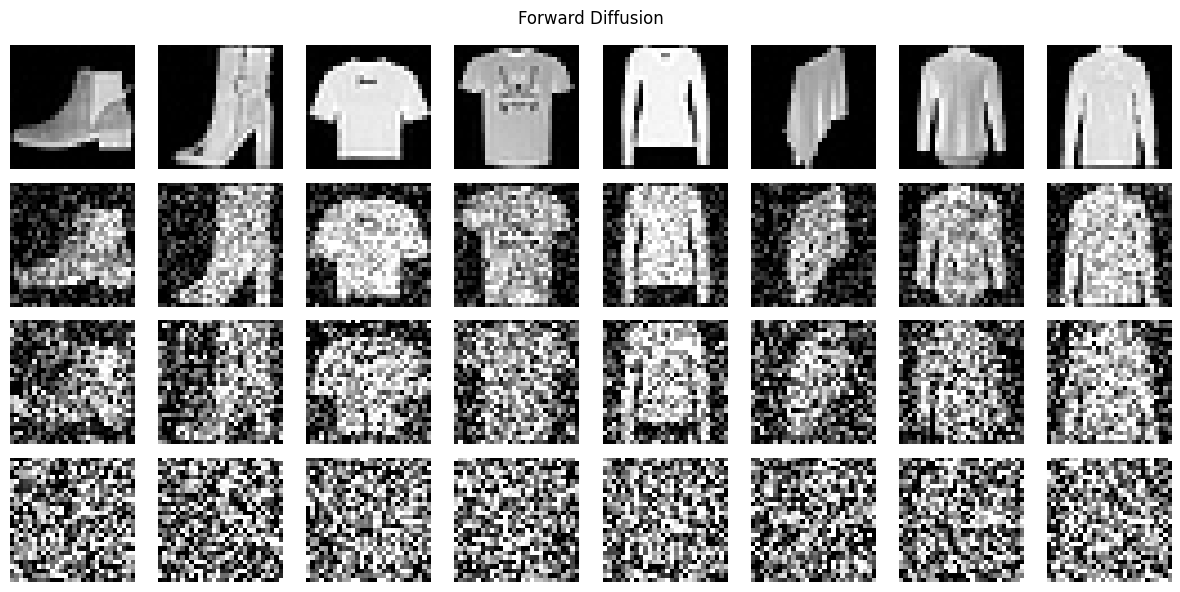

In [10]:
images, labels = next(iter(train_loader))
x_start = images[:8].to(device)

steps = [0, TIMESTEPS // 4, TIMESTEPS // 2, TIMESTEPS - 1]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for row, step in enumerate(steps):
    t = torch.full(
        (8,), step, device=device, dtype=torch.long
    )

    noisy = q_sample(x_start, t)

    for col in range(8):
        axes[row, col].imshow(
            noisy[col, 0].cpu().numpy(),
            cmap="gray",
            vmin=-1,
            vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"t={step}", rotation=0, labelpad=30
    )

plt.suptitle("Forward Diffusion")
plt.tight_layout()
plt.show()

In [11]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, timesteps):
        half_dim = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half_dim,
                device=timesteps.device,
                dtype=torch.float32
            )
            / max(half_dim - 1, 1)
        )

        angles = timesteps.float()[:, None] * frequencies[None, :]

        return torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=-1
        )

In [12]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3, padding=1
        )

        self.norm1 = nn.GroupNorm(8, out_channels)

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3, padding=1
        )

        self.norm2 = nn.GroupNorm(8, out_channels)

        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_emb):
        h = self.conv1(x)
        h = self.norm1(h)

        time_features = self.time_mlp(time_emb)
        h = h + time_features[:, :, None, None]

        h = F.silu(h)
        h = self.conv2(h)
        h = self.norm2(h)

        return F.silu(h + self.shortcut(x))

In [13]:
class UNet(nn.Module):
    def __init__(self, channels=1, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, time_dim * 2),
            nn.SiLU(),
            nn.Linear(time_dim * 2, time_dim)
        )

        # Encoder
        self.init_conv = nn.Conv2d(channels, 32, 3, padding=1)

        self.down1 = ResBlock(32, 32, time_dim)
        self.downsample1 = nn.Conv2d(
            32, 64, 4, stride=2, padding=1
        )

        self.down2 = ResBlock(64, 64, time_dim)
        self.downsample2 = nn.Conv2d(
            64, 128, 4, stride=2, padding=1
        )

        self.down3 = ResBlock(128, 128, time_dim)

        # Bottleneck
        self.mid1 = ResBlock(128, 128, time_dim)
        self.mid2 = ResBlock(128, 128, time_dim)

        # Decoder
        self.up2_proj = nn.Conv2d(128, 64, 1)
        self.up2 = ResBlock(128, 64, time_dim)

        self.up1_proj = nn.Conv2d(64, 32, 1)
        self.up1 = ResBlock(64, 32, time_dim)

        # Predict noise, not the clean image
        self.final_conv = nn.Sequential(
            nn.Conv2d(32, 32, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(32, channels, 1)
        )

    def forward(self, x, timesteps):
        time_emb = self.time_embedding(timesteps)

        # Encoder
        x = self.init_conv(x)

        h1 = self.down1(x, time_emb)

        h2 = self.downsample1(h1)
        h2 = self.down2(h2, time_emb)

        h3 = self.downsample2(h2)
        h3 = self.down3(h3, time_emb)

        # Bottleneck
        h = self.mid1(h3, time_emb)
        h = self.mid2(h, time_emb)

        # Decoder with skip connections
        h = F.interpolate(
            h, size=h2.shape[-2:], mode="nearest"
        )
        h = self.up2_proj(h)
        h = torch.cat([h, h2], dim=1)
        h = self.up2(h, time_emb)

        h = F.interpolate(
            h, size=h1.shape[-2:], mode="nearest"
        )
        h = self.up1_proj(h)
        h = torch.cat([h, h1], dim=1)
        h = self.up1(h, time_emb)

        return self.final_conv(h)

In [14]:
model = UNet(channels=CHANNELS).to(device)

test_images = torch.randn(4, 1, 28, 28, device=device)
test_timesteps = torch.randint(
    0, TIMESTEPS, (4,), device=device
)

with torch.no_grad():
    predicted_noise = model(test_images, test_timesteps)

print("Input shape:", test_images.shape)
print("Output shape:", predicted_noise.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 1, 28, 28])
Parameters: 1453121


In [15]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

loss_history = []

for epoch in range(EPOCHS):
    model.train()

    epoch_loss = 0.0
    start_time = time.time()

    for images, _ in train_loader:
        images = images.to(device)

        batch_size = images.shape[0]

        # Sample a random timestep for each image
        t = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )

        # Generate the actual Gaussian noise
        noise = torch.randn_like(images)

        # Create the noisy images
        x_noisy = q_sample(images, t, noise)

        # Predict the noise
        predicted_noise = model(x_noisy, t)

        # Noise-prediction loss
        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    loss_history.append(epoch_loss)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.5f} "
        f"Time: {elapsed:.1f}s"
    )

Epoch [1/5] Loss: 0.35041 Time: 6.4s
Epoch [2/5] Loss: 0.15272 Time: 5.5s
Epoch [3/5] Loss: 0.12336 Time: 5.5s
Epoch [4/5] Loss: 0.11138 Time: 5.6s
Epoch [5/5] Loss: 0.10512 Time: 6.1s


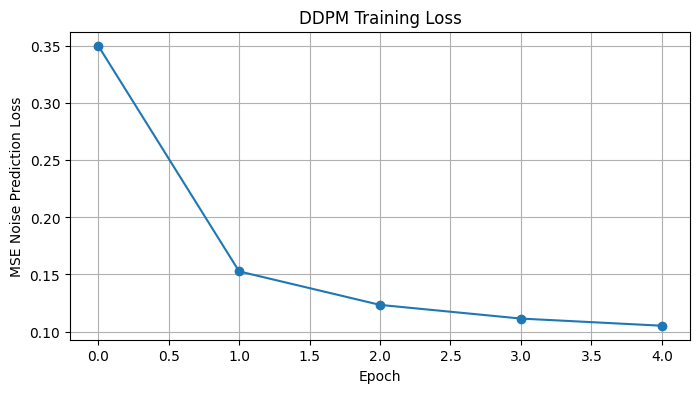

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE Noise Prediction Loss")
plt.title("DDPM Training Loss")
plt.grid(True)
plt.show()

In [17]:
@torch.no_grad()
def p_sample(model, x, t):
    beta_t = extract(beta, t, x.shape)
    sqrt_one_minus_alpha_bar_t = extract(
        sqrt_one_minus_alpha_bar, t, x.shape
    )
    sqrt_recip_alpha_t = extract(
        sqrt_recip_alpha, t, x.shape
    )

    # Predict noise
    predicted_noise = model(x, t)

    # Mean of the reverse transition
    model_mean = sqrt_recip_alpha_t * (
        x
        - beta_t
        / sqrt_one_minus_alpha_bar_t
        * predicted_noise
    )

    # Add noise unless this is the final step
    if (t == 0).all():
        return model_mean

    variance_t = extract(posterior_variance, t, x.shape)

    noise = torch.randn_like(x)

    return model_mean + torch.sqrt(variance_t) * noise


@torch.no_grad()
def sample_images(model, num_images=16, return_trajectory=False):
    model.eval()

    x = torch.randn(
        num_images, CHANNELS, IMAGE_SIZE, IMAGE_SIZE,
        device=device
    )

    trajectory = []

    for timestep in reversed(range(TIMESTEPS)):
        t = torch.full(
            (num_images,),
            timestep,
            device=device,
            dtype=torch.long
        )

        x = p_sample(model, x, t)

        if return_trajectory and (
            timestep % max(TIMESTEPS // 10, 1) == 0
            or timestep == 0
        ):
            trajectory.append((timestep, x[:4].cpu().clone()))

    # Convert model output from [-1, 1] to [0, 1]
    x = x.clamp(-1, 1)
    x = (x + 1) / 2

    if return_trajectory:
        return x, trajectory

    return x

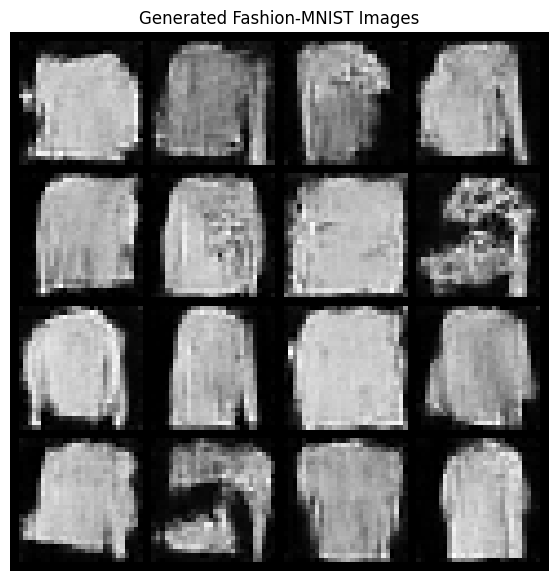

In [18]:
generated_images, trajectory = sample_images(
    model,
    num_images=16,
    return_trajectory=True
)

grid = make_grid(
    generated_images.cpu(),
    nrow=4,
    padding=2
)

plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("Generated Fashion-MNIST Images")
plt.axis("off")
plt.show()

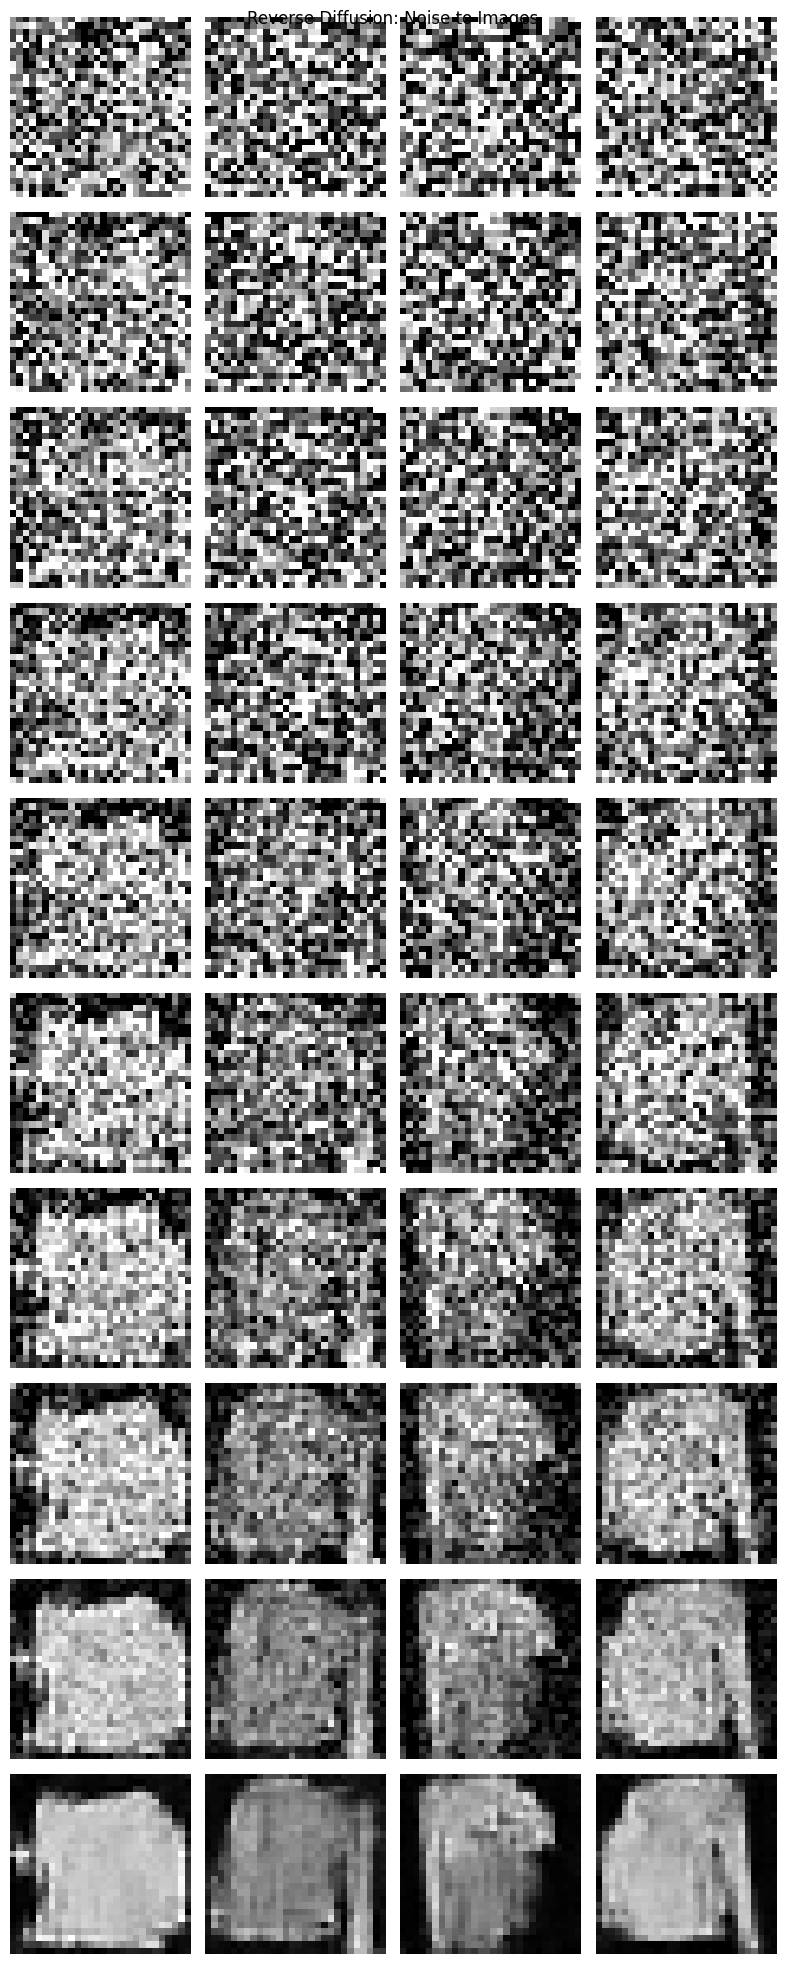

In [19]:
fig, axes = plt.subplots(
    len(trajectory), 4,
    figsize=(8, 2 * len(trajectory))
)

for row, (timestep, batch) in enumerate(trajectory):
    for col in range(4):
        img = batch[col, 0].numpy()

        # Display each intermediate image in a consistent range
        axes[row, col].imshow(
            img, cmap="gray", vmin=-1, vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"t={timestep}", rotation=0, labelpad=30
    )

plt.suptitle("Reverse Diffusion: Noise to Images")
plt.tight_layout()
plt.show()